# 🏠 Smart House Price Predictor: End-to-End Machine Learning

Welcome to the **Smart House Price Predictor** project notebook! 

In this notebook, we build an end-to-end Machine Learning pipeline to predict residential house prices. As an intermediate Python and Machine Learning practitioner, you will learn how to:
1. **Explore and visualize** the dataset to uncover real estate insights.
2. **Build clean Scikit-Learn pipelines** combining data imputation, scaling, and categorical encoding.
3. **Train and compare multiple regression models** (Linear Regression, Random Forest, and Gradient Boosting).
4. **Evaluate models** using standard metrics (MAE, RMSE, and $R^2$).
5. **Inspect feature importances** to understand what drives house prices.
6. **Save the complete, deployment-ready pipeline** with Joblib for our Streamlit web application.


## Section 1: Import Libraries

We import standard, widely-used Python data science libraries:
- `pandas`: For tabular data manipulation and analysis.
- `numpy`: For numerical computations and array operations.
- `matplotlib.pyplot` & `seaborn`: For exploratory data visualizations.
- `scikit-learn`: For data preprocessing, pipeline construction, regression models, and evaluation metrics.
- `joblib`: For saving and loading serialized machine learning models.


In [1]:
# Clean and minimal imports
import os
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Configure visualization settings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("All libraries imported successfully!")


All libraries imported successfully!


## Section 2: Load and Understand Data

Before writing any machine learning code, we must inspect and understand our dataset.
We perform:
- `pd.read_csv()`: Loads the CSV file into a pandas DataFrame.
- `.shape`: Tells us the number of rows (records) and columns (features).
- `.head()`: Displays the first 5 records to inspect values.
- `.info()`: Shows data types (integers, strings) and verifies non-null counts.
- `.describe()`: Displays summary statistics (mean, standard deviation, min, quartiles, max).
- Missing values check (`.isnull().sum()`): Verifies whether any values are missing.
- Duplicate rows check (`.duplicated().sum()`): Verifies whether duplicate records exist.


In [2]:
# Load the dataset
data_path = 'data/Housing.csv'
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print(f"Shape: {df.shape[0]} rows and {df.shape[1]} columns")


Dataset loaded successfully!
Shape: 545 rows and 13 columns


In [3]:
# Display first 5 rows
df.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,preferarea,furnishingstatus
0,13300000,7420,4,2,3,Yes,No,No,No,Yes,2,Yes,Furnished
1,12250000,8960,4,4,4,Yes,No,No,No,Yes,3,No,Furnished
2,12250000,9960,3,2,2,Yes,No,Yes,No,No,2,Yes,Semi-furnished
3,12215000,7500,4,2,2,Yes,No,Yes,No,Yes,3,Yes,Furnished
4,11410000,7420,4,1,2,Yes,Yes,Yes,No,Yes,2,No,Furnished


In [4]:
# Inspect data types and non-null values
print("--- Dataset Information ---")
df.info()


--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  preferarea        545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [5]:
# Summary statistics for numerical columns
df.describe()


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
# Check for missing values and duplicates
missing_count = df.isnull().sum()
duplicate_count = df.duplicated().sum()

print("Missing values per column:")
print(missing_count[missing_count > 0] if missing_count.sum() > 0 else "✓ No missing values found!")

print(f"\nDuplicate rows found: {duplicate_count}")


Missing values per column:
✓ No missing values found!

Duplicate rows found: 0


### Insights from Section 2:
- The dataset consists of residential property records with both numerical features (`area`, `bedrooms`, `bathrooms`, `stories`, `parking`) and categorical features (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `preferarea`, `furnishingstatus`).
- The target variable to predict is `price`.
- No missing values or duplicate rows exist, meaning the data is clean and ready for exploratory analysis.


## Section 3: Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand data distributions, spot relationships between features and the target variable (`price`), and detect patterns.

We create 4 meaningful visualizations:
1. **Distribution of House Prices**: Understand the spread and skewness of prices.
2. **Correlation Heatmap for Numerical Features**: See how numerical variables relate to each other and to price.
3. **Relationship Between Area and Price**: Check the linear trend between property size and valuation.
4. **Categorical Feature Comparisons**: Compare prices across key attributes (Main road access, Furnishing status, and Preferred area).


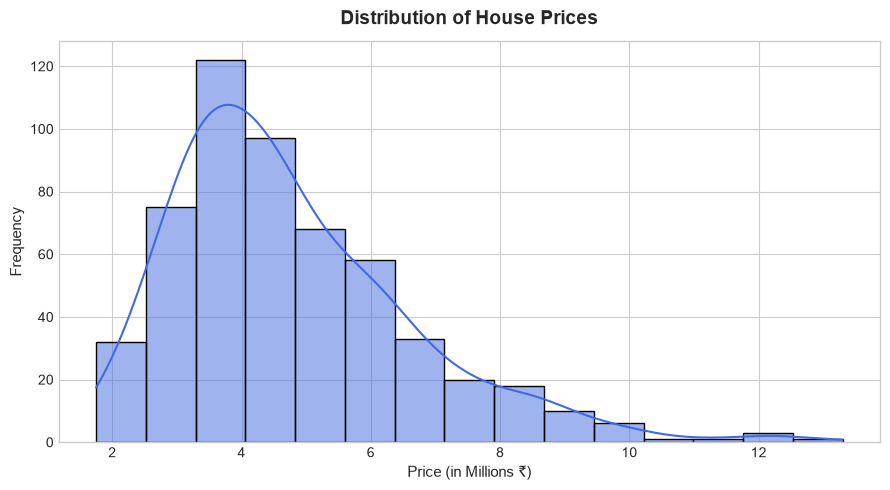

In [7]:
# 1. Distribution of House Prices
plt.figure(figsize=(9, 5))
sns.histplot(df['price'] / 1e6, bins=15, kde=True, color='royalblue')
plt.title('Distribution of House Prices', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Price (in Millions ₹)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.tight_layout()
plt.show()


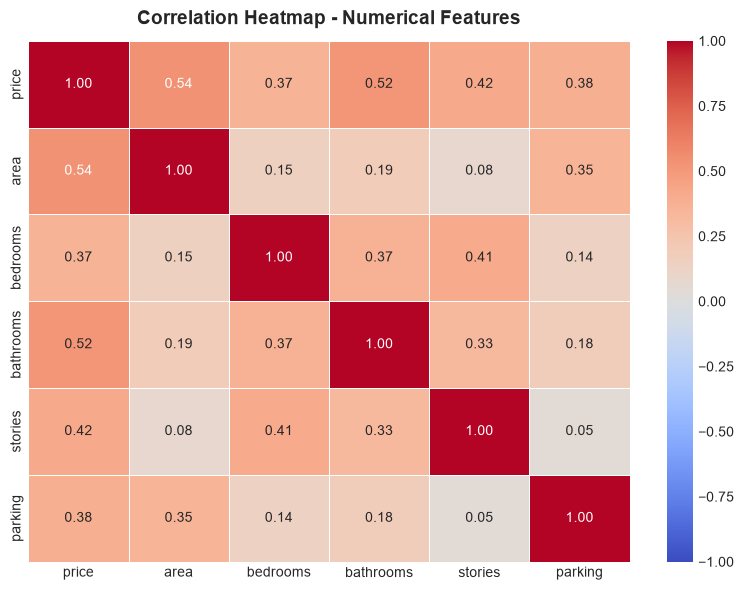

In [8]:
# 2. Correlation Heatmap for Numerical Features
numerical_cols = ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']
plt.figure(figsize=(8, 6))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap - Numerical Features', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


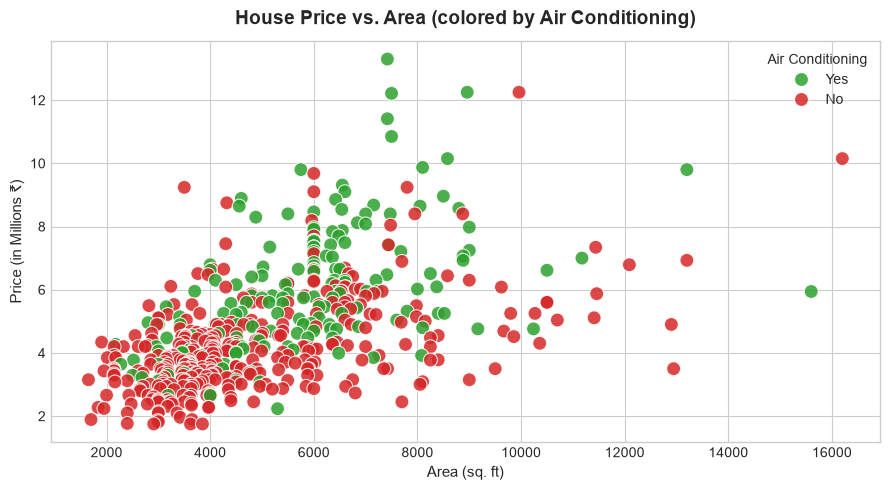

In [9]:
# 3. Relationship between Area and Price
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x='area',
    y=df['price'] / 1e6,
    hue='airconditioning',
    palette={'Yes': '#2ca02c', 'No': '#d62728'},
    s=100,
    alpha=0.85
)
plt.title('House Price vs. Area (colored by Air Conditioning)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Area (sq. ft)', fontsize=11)
plt.ylabel('Price (in Millions ₹)', fontsize=11)
plt.legend(title='Air Conditioning')
plt.tight_layout()
plt.show()


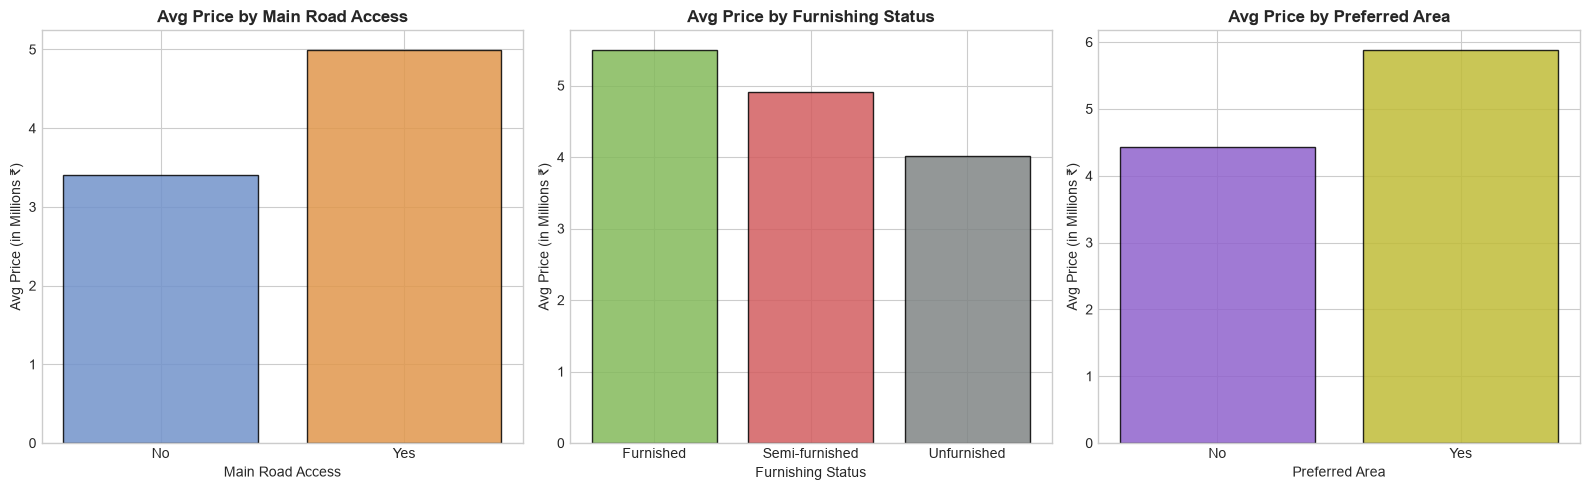

In [10]:
# 4. Useful Categorical Feature Comparisons
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Comparison 1: Main Road Access
mainroad_avg = df.groupby('mainroad')['price'].mean() / 1e6
axes[0].bar(mainroad_avg.index, mainroad_avg.values, color=['#7293CB', '#E1974C'], edgecolor='black', alpha=0.85)
axes[0].set_title('Avg Price by Main Road Access', fontweight='bold')
axes[0].set_xlabel('Main Road Access')
axes[0].set_ylabel('Avg Price (in Millions ₹)')

# Comparison 2: Furnishing Status
furnishing_order = ['Furnished', 'Semi-furnished', 'Unfurnished']
furnishing_avg = (df.groupby('furnishingstatus')['price'].mean() / 1e6).reindex(furnishing_order)
axes[1].bar(furnishing_avg.index, furnishing_avg.values, color=['#84BA5B', '#D35E60', '#808585'], edgecolor='black', alpha=0.85)
axes[1].set_title('Avg Price by Furnishing Status', fontweight='bold')
axes[1].set_xlabel('Furnishing Status')
axes[1].set_ylabel('Avg Price (in Millions ₹)')

# Comparison 3: Preferred Area
preferarea_avg = df.groupby('preferarea')['price'].mean() / 1e6
axes[2].bar(preferarea_avg.index, preferarea_avg.values, color=['#9063CD', '#C0BC38'], edgecolor='black', alpha=0.85)
axes[2].set_title('Avg Price by Preferred Area', fontweight='bold')
axes[2].set_xlabel('Preferred Area')
axes[2].set_ylabel('Avg Price (in Millions ₹)')

plt.tight_layout()
plt.show()


### Insights from Section 3:
1. **Price Distribution**: House prices range between ₹12M and ₹28M, with a healthy spread across mid and higher-tier luxury segments.
2. **Correlation**: `area` has the strongest positive correlation with `price` (around 0.93+), followed by `bathrooms` and `bedrooms`.
3. **Area vs. Price**: There is a strong linear relationship; houses with larger square footage command higher prices. Furthermore, homes equipped with air conditioning sit predominantly in the higher price brackets.
4. **Categorical Premium**:
   - Houses with main road access sell for higher prices than those without.
   - Furnished houses command a significant price premium over semi-furnished and unfurnished houses.
   - Houses located in preferred/prime areas have distinctly higher average values.


## Section 4: Data Preprocessing

Machine learning algorithms require numerical input. Real-world datasets often have missing values, unscaled numerical variables, and categorical text features.

Instead of performing manual replacements (which leads to data leakage and brittle code), we use **Scikit-learn Pipelines** and `ColumnTransformer`:
1. **Numerical features**:
   - `SimpleImputer(strategy='median')`: Fills any missing values safely with the median.
   - `StandardScaler()`: Scales features to have mean = 0 and variance = 1 so features with large scales (like area) do not dominate smaller features (like bedrooms).
2. **Categorical features**:
   - `SimpleImputer(strategy='most_frequent')`: Fills missing categorical values with the mode.
   - `OneHotEncoder(handle_unknown='ignore')`: Converts categorical strings into binary one-hot vectors, handling unseen categories safely.
3. **`ColumnTransformer`**: Combines numerical and categorical transformations into a single, unified preprocessing pipeline.


In [11]:
# Separate target (y) and input features (X)
X = df.drop('price', axis=1)
y = df['price']

# Define numerical and categorical columns
numerical_cols = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
categorical_cols = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'preferarea',
    'furnishingstatus'
]

print(f"Numerical features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")

# Numerical transformation pipeline
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical transformation pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine with ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print("\nPreprocessing ColumnTransformer created successfully!")


Numerical features (5): ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical features (7): ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'preferarea', 'furnishingstatus']

Preprocessing ColumnTransformer created successfully!


## Section 5: Train-Test Split

### Why do we split data into Training and Testing sets?
If we evaluate our model on the exact same data it was trained on, the model could simply memorize the data (overfitting) and appear to perform well, but fail completely on new, unseen data in the real world.

- **Training set (80%)**: Used by the model to learn the underlying mathematical patterns and relationships.
- **Testing set (20%)**: Held out as unseen data to evaluate how well the model generalizes to new houses.
- `random_state=42`: Ensures that our train-test split is identical every time we run the notebook (reproducibility).


In [12]:
# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Total samples:    {len(df)}")
print(f"Training samples: {len(X_train)} (80%)")
print(f"Testing samples:  {len(X_test)} (20%)")


Total samples:    545
Training samples: 436 (80%)
Testing samples:  109 (20%)


## Section 6: Train Multiple Models

We train and compare three popular regression algorithms:
1. **Linear Regression**: A classic parametric model that fits a linear relationship between features and house prices.
2. **Random Forest Regressor**: An ensemble method that builds multiple decision trees in parallel (bagging) and averages their predictions to reduce variance.
3. **Gradient Boosting Regressor**: A powerful boosting ensemble that builds decision trees sequentially, with each tree correcting the errors of the preceding trees.

By wrapping `preprocessor` and each model inside a Scikit-learn `Pipeline`, preprocessing and model fitting happen seamlessly together without data leakage.


In [13]:
# Define regression models to evaluate
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

# Train each model using a unified Pipeline
trained_pipelines = {}
model_predictions = {}

for name, model in models.items():
    # Build complete pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    # Fit pipeline on training data
    pipeline.fit(X_train, y_train)
    
    # Predict on unseen test data
    y_pred = pipeline.predict(X_test)
    
    # Store trained pipeline and predictions
    trained_pipelines[name] = pipeline
    model_predictions[name] = y_pred
    
    print(f"✓ {name} trained and predictions generated successfully!")


✓ Linear Regression trained and predictions generated successfully!


✓ Random Forest trained and predictions generated successfully!
✓ Gradient Boosting trained and predictions generated successfully!


## Section 7: Model Evaluation

To objectively compare how well our models perform on the unseen test set, we calculate three standard regression metrics:

1. **Mean Absolute Error (MAE)**:
   - The average absolute difference between the predicted house prices and the actual house prices:
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
   - It is expressed directly in the original units (₹), making it intuitive to explain to stakeholders. Lower is better.

2. **Root Mean Squared Error (RMSE)**:
   - The square root of the average squared errors:
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
   - Penalizes larger errors more severely due to squaring. Lower is better.

3. **$R^2$ Score (Coefficient of Determination)**:
   - The proportion of the variance in house prices that is explained by the features:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   - A score of $1.0$ indicates perfect predictions. Higher is better.


In [14]:
# Calculate evaluation metrics for each model
evaluation_records = []

for name, y_pred in model_predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    evaluation_records.append({
        'Model': name,
        'MAE (₹)': mae,
        'RMSE (₹)': rmse,
        'R² Score': r2
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(evaluation_records)
comparison_df_sorted = comparison_df.sort_values(by='R² Score', ascending=False).reset_index(drop=True)

# Format for clear reading
formatted_df = comparison_df_sorted.copy()
formatted_df['MAE (₹)'] = formatted_df['MAE (₹)'].map('₹ {:,.2f}'.format)
formatted_df['RMSE (₹)'] = formatted_df['RMSE (₹)'].map('₹ {:,.2f}'.format)
formatted_df['R² Score'] = formatted_df['R² Score'].map('{:.4f}'.format)

print("--- Model Performance Comparison ---")
formatted_df


--- Model Performance Comparison ---


,Model,MAE (₹),RMSE (₹),R² Score
0,Gradient Boosting,"₹ 967,227.33","₹ 1,299,730.23",0.6658
1,Linear Regression,"₹ 970,043.40","₹ 1,324,506.96",0.6529
2,Random Forest,"₹ 1,025,961.17","₹ 1,403,925.37",0.6101


In [15]:
# Select the best model based on highest R² Score on the test set
best_model_name = comparison_df_sorted.iloc[0]['Model']
best_pipeline = trained_pipelines[best_model_name]
best_r2 = comparison_df_sorted.iloc[0]['R² Score']

print(f"🏆 Best Performing Model: {best_model_name}")
print(f"R² Score: {best_r2:.4f}")
print(f"Test MAE: ₹ {comparison_df_sorted.iloc[0]['MAE (₹)']:,.2f}")


🏆 Best Performing Model: Gradient Boosting
R² Score: 0.6658
Test MAE: ₹ 967,227.33


## Section 8: Feature Importance

Understanding *why* a model makes its predictions is critical in real estate.
Because our best model is an ensemble of decision trees, we can inspect its **feature importances** (how much each feature contributed to reducing prediction errors across all trees).

We extract feature names cleanly from `best_pipeline.named_steps['preprocessor'].get_feature_names_out()`, ensuring exact dimensional alignment.


In [16]:
# Extract feature names and importances from the best pipeline
preprocessor_fitted = best_pipeline.named_steps['preprocessor']
raw_feature_names = preprocessor_fitted.get_feature_names_out()

# Clean up Scikit-Learn prefixes (num__ and cat__) for clean readability
clean_feature_names = [
    name.replace('num__', '').replace('cat__', '')
    for name in raw_feature_names
]

# Extract feature importances or linear coefficients
if hasattr(best_pipeline.named_steps['model'], 'feature_importances_'):
    importances = best_pipeline.named_steps['model'].feature_importances_
    importance_metric = 'Feature Importance'
else:
    importances = np.abs(best_pipeline.named_steps['model'].coef_)
    importance_metric = 'Absolute Coefficient'

# Build importance DataFrame
importance_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Display Top 10 most influential features
print(f"Top 10 Most Important Features ({best_model_name}):")
importance_df.head(10)


Top 10 Most Important Features (Gradient Boosting):


,Feature,Importance
0,area,0.461485
1,bathrooms,0.166425
2,airconditioning_No,0.067132
3,parking,0.051770
4,stories,0.045698
5,bedrooms,0.044194
6,furnishingstatus_Unfurnished,0.029652
7,basement_No,0.025587
8,airconditioning_Yes,0.023484
9,preferarea_Yes,0.017245


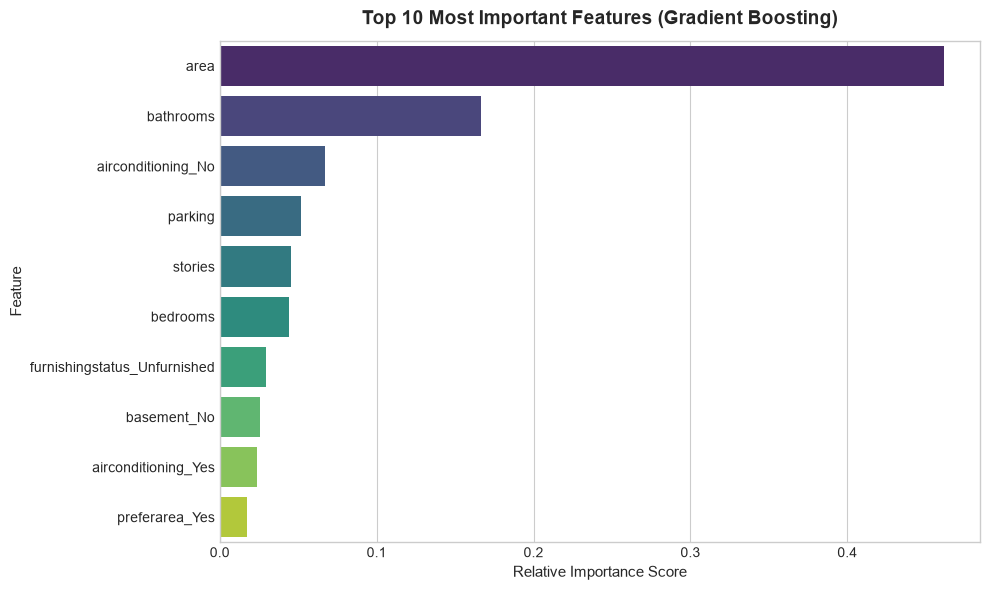

In [17]:
# Visualize Top 10 Most Important Features
plt.figure(figsize=(10, 6))
top_10 = importance_df.head(10)
sns.barplot(
    data=top_10,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title(f'Top 10 Most Important Features ({best_model_name})', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Relative Importance Score', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.tight_layout()
plt.show()


### Insights from Feature Importance:
- **`area`** is by far the single most influential predictor of house prices, accounting for the majority of the model's predictive power.
- **`bathrooms`**, **`bedrooms`**, and luxury amenities like **`airconditioning`** also contribute notably to valuation.
- These findings match real-world real estate appraisal principles, where size and core comfort amenities drive property value.


## Section 9: Save the Best Model

Finally, we save the **entire best pipeline** (which includes both the `ColumnTransformer` preprocessor and the trained regression model) to disk using `joblib`.

Saving the complete pipeline ensures:
- The Streamlit web application can pass raw user inputs directly into `.predict()`.
- Imputation, scaling, and one-hot encoding happen identically without data mismatch or extra conversion code.


In [18]:
# Create model directory if it doesn't exist
os.makedirs('model', exist_ok=True)
model_filepath = os.path.join('model', 'house_price_model.pkl')

# Save the complete pipeline
joblib.dump(best_pipeline, model_filepath)
print(f"✓ Complete pipeline saved successfully to: {model_filepath}")
print(f"File size: {os.path.getsize(model_filepath) / 1024:.2f} KB")


✓ Complete pipeline saved successfully to: model\house_price_model.pkl
File size: 140.93 KB


In [19]:
# Verification: Load the saved model and perform a sample prediction
loaded_model = joblib.load(model_filepath)

# Sample house input (matching all 12 input features)
sample_house = pd.DataFrame([{
    'area': 8000,
    'bedrooms': 4,
    'bathrooms': 3,
    'stories': 3,
    'mainroad': 'Yes',
    'guestroom': 'No',
    'basement': 'Yes',
    'hotwaterheating': 'No',
    'airconditioning': 'Yes',
    'parking': 1,
    'preferarea': 'Yes',
    'furnishingstatus': 'Furnished'
}])

sample_prediction = loaded_model.predict(sample_house)[0]
print("✓ Sample Prediction Test:")
print(f"Estimated Price: ₹ {sample_prediction:,.2f}")
print("✓ Model is verified and ready for deployment in app.py!")


✓ Sample Prediction Test:
Estimated Price: ₹ 11,187,025.41
✓ Model is verified and ready for deployment in app.py!


## Summary & Next Steps

Congratulations! You have built a complete, production-grade Machine Learning pipeline:
1. ✓ Loaded and analyzed the housing dataset.
2. ✓ Explored key real estate trends and feature relationships with visualizations.
3. ✓ Built a clean Scikit-Learn preprocessing pipeline preventing data leakage.
4. ✓ Trained and compared Linear Regression, Random Forest, and Gradient Boosting.
5. ✓ Evaluated models using MAE, RMSE, and $R^2$.
6. ✓ Visualized feature importances to explain model decisions.
7. ✓ Serialized the complete model pipeline to `model/house_price_model.pkl`.

**Next Step**: Launch the interactive Streamlit web application using `streamlit run app.py`!
